In [2]:
# Вариант 5
%pip install seaborn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

order_files = [
    "orders_2024_01.csv",
    "orders_2024_02.csv",
    "orders_2024_03.csv"
]

df_orders = pd.concat(
    [pd.read_csv(file) for file in order_files],
    ignore_index=True
)

df_orders["order_datetime"] = pd.to_datetime(
    df_orders["order_datetime"]
)

df_orders["revenue"] = (
    df_orders["price"] * df_orders["quantity"]
)

print("Таблица заказов:")
print(df_orders.head())

Таблица заказов:
   order_id  user_id      order_datetime  product_id     price  quantity  \
0         1     1044 2024-01-03 18:39:26          26  14038.15         1   
1         2     1079 2024-01-03 17:45:43          16   9172.60         1   
2         3     1041 2024-01-06 22:46:38          25   9035.26         2   
3         4     1083 2024-01-08 21:03:51           9  15234.33         3   
4         5     1068 2024-01-03 23:26:53          24   4134.38         2   

     status   revenue  
0  refunded  14038.15  
1      paid   9172.60  
2      paid  18070.52  
3      paid  45702.99  
4      paid   8268.76  


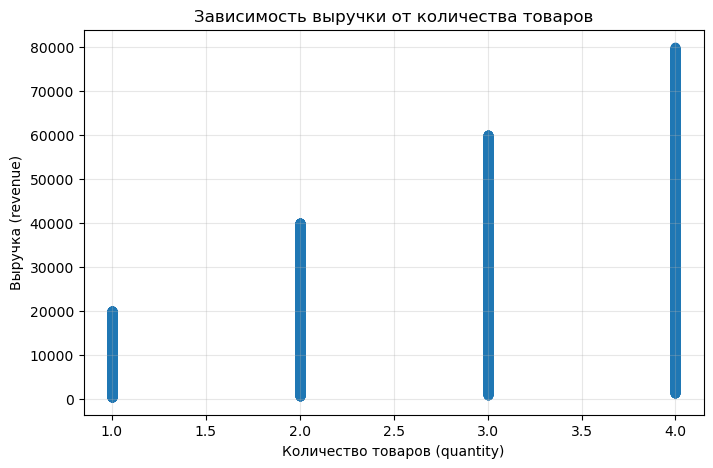

In [3]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_orders["quantity"],
    df_orders["revenue"]
)

plt.title("Зависимость выручки от количества товаров")
plt.xlabel("Количество товаров (quantity)")
plt.ylabel("Выручка (revenue)")
plt.grid(True, alpha=0.3)
plt.show()

In [4]:
correlation = df_orders["quantity"].corr(df_orders["revenue"])

print("\nЗадание 2. Корреляция между quantity и revenue:")
print(correlation)


Задание 2. Корреляция между quantity и revenue:
0.5999202576554735


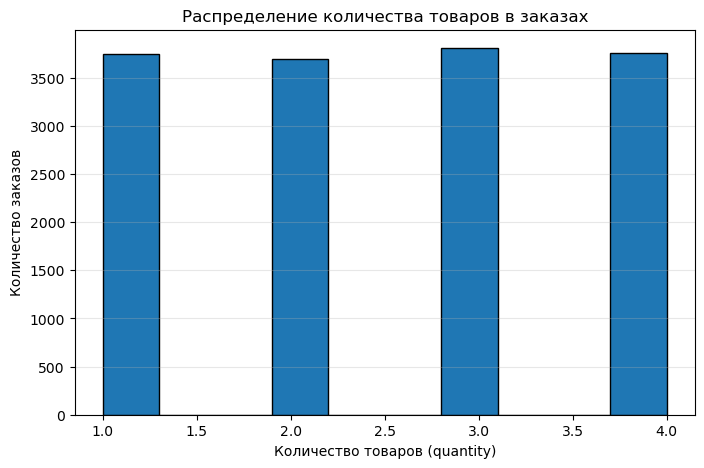

In [5]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_orders["quantity"],
    bins=10,
    edgecolor="black"
)

plt.title("Распределение количества товаров в заказах")
plt.xlabel("Количество товаров (quantity)")
plt.ylabel("Количество заказов")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [6]:
percentile_95 = df_orders["quantity"].quantile(0.95)

orders_above_95 = df_orders[
    df_orders["quantity"] > percentile_95
]

print("\nЗадание 4. 95-й перцентиль quantity:")
print(percentile_95)

print("\nЗаказы с quantity выше 95-го перцентиля:")
print(orders_above_95)

print("\nКоличество найденных заказов:")
print(orders_above_95.shape[0])


Задание 4. 95-й перцентиль quantity:
4.0

Заказы с quantity выше 95-го перцентиля:
Empty DataFrame
Columns: [order_id, user_id, order_datetime, product_id, price, quantity, status, revenue]
Index: []

Количество найденных заказов:
0


In [ ]:
В ходе практической работы была построена диаграмма рассеяния зависимости выручки от количества товаров в заказе. 
Рассчитанный коэффициент корреляции Пирсона составил 0,60, что указывает на умеренную положительную связь между количеством товаров и выручкой. 
Построенная гистограмма показала, что количество товаров в заказах варьируется от 1 до 4. 
Для поиска заказов с большим количеством товаров был рассчитан 95-й перцентиль, равный 4. 
Поскольку значение перцентиля совпадает с максимальным количеством товаров в выборке, заказов со значением quantity выше данного порога не обнаружено. 
Таким образом, увеличение количества товаров в заказе в целом связано с ростом выручки, однако на её величину также влияет цена товаров.